In [1]:
!pip install -q roboflow ultralytics pyyaml

from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

user_secrets = UserSecretsClient()
api_key = user_secrets.get_secret("ROBOFLOW_API_KEY")

rf = Roboflow(api_key=api_key)
project = rf.workspace("joseph-nelson").project("hard-hat-workers")
version = project.version(10)
dataset = version.download("yolov11")

print("Dataset location:", dataset.location)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Hard-Hat-Workers-10 in yolov11:: 100%|██████████| 14082/14082 [00:01<00:00, 8250.31it/s]


Dataset location: /kaggle/working/Hard-Hat-Workers-10


In [2]:
from pathlib import Path
import os

DATASET_PATH = Path(dataset.location)

print("Dataset path:", DATASET_PATH)
print("\nFiles and folders:")

for item in DATASET_PATH.iterdir():
    print(item.name)

Dataset path: /kaggle/working/Hard-Hat-Workers-10

Files and folders:
train
README.roboflow.txt
valid
test
README.dataset.txt
data.yaml


In [3]:
import yaml

yaml_path = DATASET_PATH / "data.yaml"

with open(yaml_path, "r") as file:
    data = yaml.safe_load(file)

print("Dataset configuration:")
print(data)

print("\nClasses:")
names = data["names"]

if isinstance(names, dict):
    for class_id, class_name in names.items():
        print(class_id, ":", class_name)
else:
    for class_id, class_name in enumerate(names):
        print(class_id, ":", class_name)

Dataset configuration:
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 3, 'names': ['head', 'helmet', 'person'], 'roboflow': {'workspace': 'joseph-nelson', 'project': 'hard-hat-workers', 'version': 10, 'license': 'Public Domain', 'url': 'https://universe.roboflow.com/joseph-nelson/hard-hat-workers/dataset/10'}}

Classes:
0 : head
1 : helmet
2 : person


In [4]:
from pathlib import Path

print("Dataset root:", DATASET_PATH)

for folder in ["train", "valid", "test"]:
    images_folder = DATASET_PATH / folder / "images"
    labels_folder = DATASET_PATH / folder / "labels"

    print(f"\n{folder}:")
    print("Images folder exists:", images_folder.exists())
    print("Labels folder exists:", labels_folder.exists())

    if images_folder.exists():
        print("Number of images:", len(list(images_folder.glob("*"))))

    if labels_folder.exists():
        print("Number of labels:", len(list(labels_folder.glob("*.txt"))))

Dataset root: /kaggle/working/Hard-Hat-Workers-10

train:
Images folder exists: True
Labels folder exists: True
Number of images: 4916
Number of labels: 4916

valid:
Images folder exists: True
Labels folder exists: True
Number of images: 1413
Number of labels: 1413

test:
Images folder exists: True
Labels folder exists: True
Number of images: 706
Number of labels: 706


Number of training images: 4916


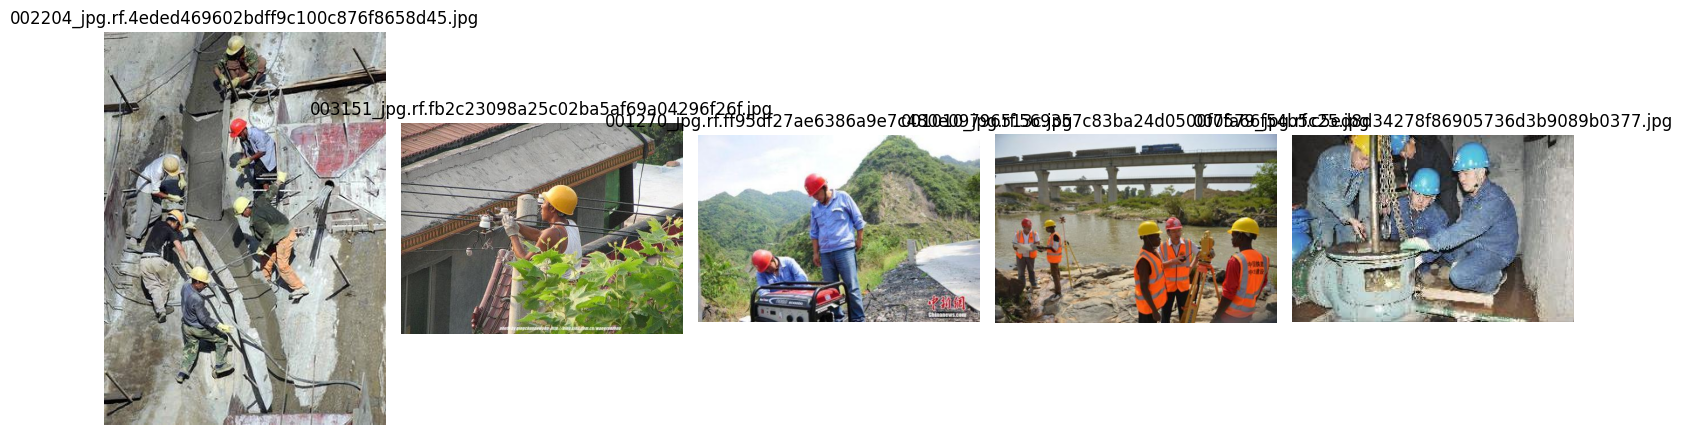

In [5]:
import matplotlib.pyplot as plt
from PIL import Image
import random

train_images = list((DATASET_PATH / "train" / "images").glob("*"))

print("Number of training images:", len(train_images))

sample_images = random.sample(
    train_images,
    min(5, len(train_images))
)

plt.figure(figsize=(15, 8))

for i, image_path in enumerate(sample_images):
    image = Image.open(image_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")

plt.tight_layout()
plt.show()

Counter({'helmet': 13919, 'head': 4612, 'person': 450})


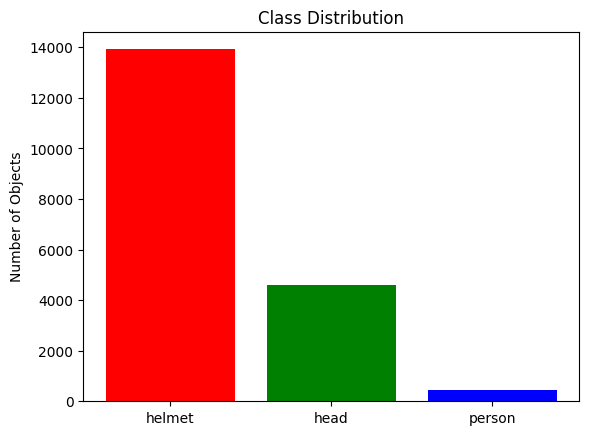

In [6]:
from collections import Counter

counts = Counter()

label_files = list((DATASET_PATH / "train" / "labels").glob("*.txt"))

for file in label_files:
    for line in open(file):
        class_id = int(line.split()[0])
        counts[data["names"][class_id]] += 1

print(counts)

plt.bar(counts.keys(), counts.values(), color=["red", "green", "blue"])
plt.title("Class Distribution")
plt.ylabel("Number of Objects")
plt.show()

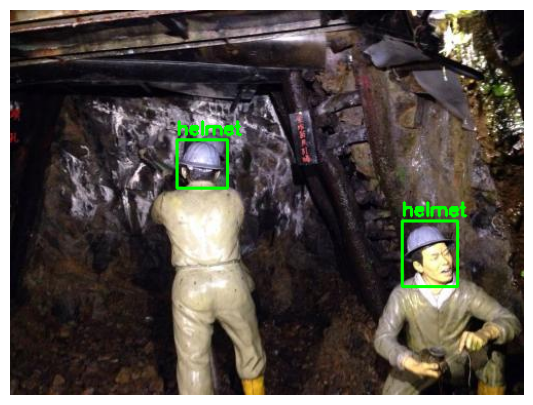

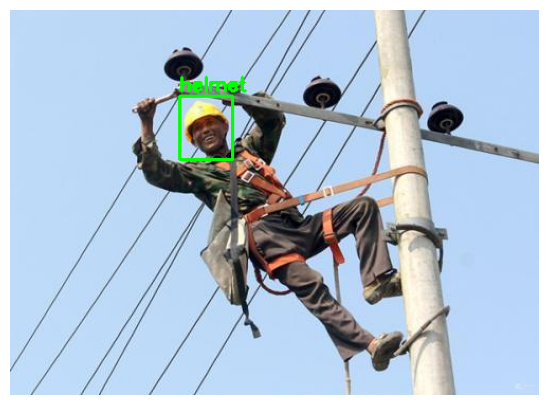

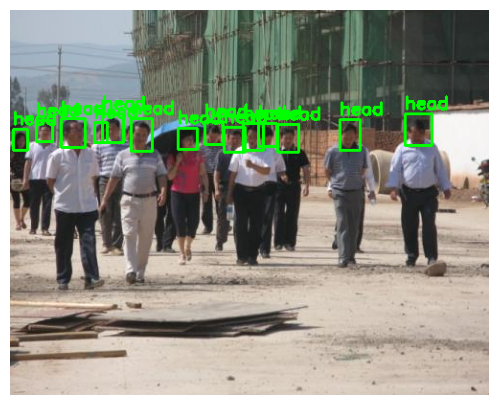

In [7]:
import cv2

samples = random.sample(train_images, 3)
class_names = data["names"]

for img_path in samples:
    img = cv2.imread(str(img_path))
    h, w = img.shape[:2]

    label_path = DATASET_PATH / "train" / "labels" / f"{img_path.stem}.txt"

    if label_path.exists():
        for line in open(label_path):
            cls, x, y, bw, bh = map(float, line.split())

            x1 = int((x - bw/2) * w)
            y1 = int((y - bh/2) * h)
            x2 = int((x + bw/2) * w)
            y2 = int((y + bh/2) * h)

            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(img, class_names[int(cls)], (x1, y1-5),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

    plt.figure(figsize=(7, 5))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()